In [195]:
# Importing Libraries
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler # Removed MinMaxScaler
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
import pickle
from sklearn.model_selection import GridSearchCV
import seaborn as sns
import matplotlib.pyplot as plt

In [131]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [132]:
# Load dataset
df = pd.read_csv("/content/drive/MyDrive/Parkinsson disease.csv")

Shape of dataset: (195, 24)

Missing values:
 name                0
MDVP:Fo(Hz)         0
MDVP:Fhi(Hz)        0
MDVP:Flo(Hz)        0
MDVP:Jitter(%)      0
MDVP:Jitter(Abs)    0
MDVP:RAP            0
MDVP:PPQ            0
Jitter:DDP          0
MDVP:Shimmer        0
MDVP:Shimmer(dB)    0
Shimmer:APQ3        0
Shimmer:APQ5        0
MDVP:APQ            0
Shimmer:DDA         0
NHR                 0
HNR                 0
status              0
RPDE                0
DFA                 0
spread1             0
spread2             0
D2                  0
PPE                 0
dtype: int64

Dataset Summary:
        MDVP:Fo(Hz)  MDVP:Fhi(Hz)  MDVP:Flo(Hz)  MDVP:Jitter(%)  \
count   195.000000    195.000000    195.000000      195.000000   
mean    154.228641    197.104918    116.324631        0.006220   
std      41.390065     91.491548     43.521413        0.004848   
min      88.333000    102.145000     65.476000        0.001680   
25%     117.572000    134.862500     84.291000        0.003460  

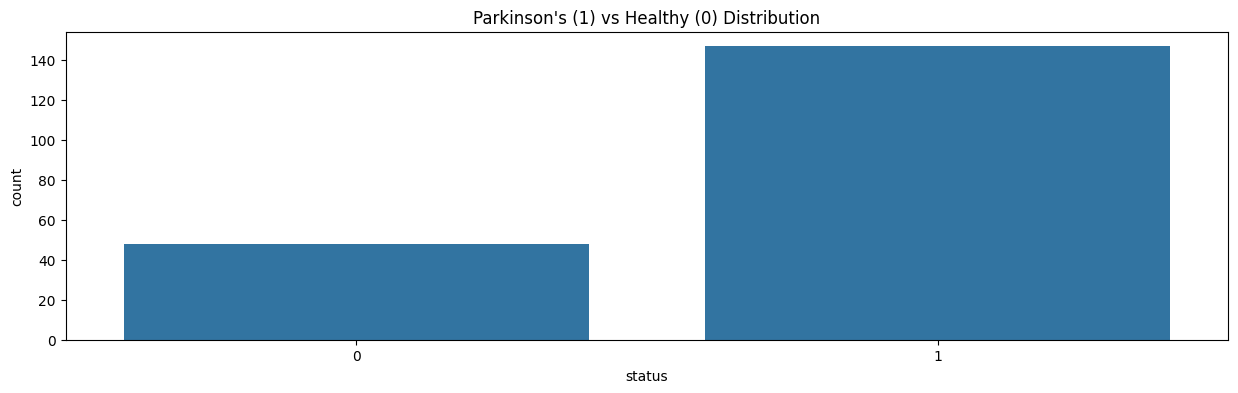

In [133]:
# --- Basic Exploratory Data Analysis ---
print("Shape of dataset:", df.shape)
print("\nMissing values:\n", df.isnull().sum())
print("\nDataset Summary:\n", df.describe())

import seaborn as sns
import matplotlib.pyplot as plt
sns.countplot(x='status', data=df)
plt.title("Parkinson's (1) vs Healthy (0) Distribution")
plt.show()


# Data Preprocessing


---
 The following steps are performed on the dataset in this section:
 + Dropping Redudant Columns
 + Checking For Duplicated Rows
 + Checking For Missing Values

In [134]:
# printing the first 5 rows of the dataframe/# Exploring Dataset Content
df.head()

,name,MDVP:Fo(Hz),MDVP:Fhi(Hz),MDVP:Flo(Hz),MDVP:Jitter(%),MDVP:Jitter(Abs),MDVP:RAP,MDVP:PPQ,Jitter:DDP,MDVP:Shimmer,...,Shimmer:DDA,NHR,HNR,status,RPDE,DFA,spread1,spread2,D2,PPE
0,phon_R01_S01_1,119.992,157.302,74.997,0.00784,0.00007,0.00370,0.00554,0.01109,0.04374,...,0.06545,0.02211,21.033,1,0.414783,0.815285,-4.813031,0.266482,2.301442,0.284654
1,phon_R01_S01_2,122.400,148.650,113.819,0.00968,0.00008,0.00465,0.00696,0.01394,0.06134,...,0.09403,0.01929,19.085,1,0.458359,0.819521,-4.075192,0.335590,2.486855,0.368674
2,phon_R01_S01_3,116.682,131.111,111.555,0.01050,0.00009,0.00544,0.00781,0.01633,0.05233,...,0.08270,0.01309,20.651,1,0.429895,0.825288,-4.443179,0.311173,2.342259,0.332634
3,phon_R01_S01_4,116.676,137.871,111.366,0.00997,0.00009,0.00502,0.00698,0.01505,0.05492,...,0.08771,0.01353,20.644,1,0.434969,0.819235,-4.117501,0.334147,2.405554,0.368975
4,phon_R01_S01_5,116.014,141.781,110.655,0.01284,0.00011,0.00655,0.00908,0.01966,0.06425,...,0.10470,0.01767,19.649,1,0.417356,0.823484,-3.747787,0.234513,2.332180,0.410335


In [135]:
 # printing last 5 rows of a DataFrame
df.tail()

,name,MDVP:Fo(Hz),MDVP:Fhi(Hz),MDVP:Flo(Hz),MDVP:Jitter(%),MDVP:Jitter(Abs),MDVP:RAP,MDVP:PPQ,Jitter:DDP,MDVP:Shimmer,...,Shimmer:DDA,NHR,HNR,status,RPDE,DFA,spread1,spread2,D2,PPE
190,phon_R01_S50_2,174.188,230.978,94.261,0.00459,0.00003,0.00263,0.00259,0.00790,0.04087,...,0.07008,0.02764,19.517,0,0.448439,0.657899,-6.538586,0.121952,2.657476,0.133050
191,phon_R01_S50_3,209.516,253.017,89.488,0.00564,0.00003,0.00331,0.00292,0.00994,0.02751,...,0.04812,0.01810,19.147,0,0.431674,0.683244,-6.195325,0.129303,2.784312,0.168895
192,phon_R01_S50_4,174.688,240.005,74.287,0.01360,0.00008,0.00624,0.00564,0.01873,0.02308,...,0.03804,0.10715,17.883,0,0.407567,0.655683,-6.787197,0.158453,2.679772,0.131728
193,phon_R01_S50_5,198.764,396.961,74.904,0.00740,0.00004,0.00370,0.00390,0.01109,0.02296,...,0.03794,0.07223,19.020,0,0.451221,0.643956,-6.744577,0.207454,2.138608,0.123306
194,phon_R01_S50_6,214.289,260.277,77.973,0.00567,0.00003,0.00295,0.00317,0.00885,0.01884,...,0.03078,0.04398,21.209,0,0.462803,0.664357,-5.724056,0.190667,2.555477,0.148569


In [136]:
# number of columns and rows in the dataframe
print('Number of Features In Dataset :', df.shape[1])
print('Number of Instances In Dataset : ', df.shape[0])

Number of Features In Dataset : 24
Number of Instances In Dataset :  195


The column **name**, is a *Redundant* column which is not useful for Analysis or Machine Learning, and will be dropped from the dataframe.

In [137]:
# Dropping The Name Column
df.drop(['name'], axis=1, inplace=True)

In [138]:
print('Number of Features In Dataset :', df.shape[1])
print('Number of Instances In Dataset : ', df.shape[0])

Number of Features In Dataset : 23
Number of Instances In Dataset :  195


In [139]:
# getting more information about the dataset
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 195 entries, 0 to 194
Data columns (total 23 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   MDVP:Fo(Hz)       195 non-null    float64
 1   MDVP:Fhi(Hz)      195 non-null    float64
 2   MDVP:Flo(Hz)      195 non-null    float64
 3   MDVP:Jitter(%)    195 non-null    float64
 4   MDVP:Jitter(Abs)  195 non-null    float64
 5   MDVP:RAP          195 non-null    float64
 6   MDVP:PPQ          195 non-null    float64
 7   Jitter:DDP        195 non-null    float64
 8   MDVP:Shimmer      195 non-null    float64
 9   MDVP:Shimmer(dB)  195 non-null    float64
 10  Shimmer:APQ3      195 non-null    float64
 11  Shimmer:APQ5      195 non-null    float64
 12  MDVP:APQ          195 non-null    float64
 13  Shimmer:DDA       195 non-null    float64
 14  NHR               195 non-null    float64
 15  HNR               195 non-null    float64
 16  status            195 non-null    int64  
 1

In [140]:
# getting some statistical measures about the data
df.describe()

,MDVP:Fo(Hz),MDVP:Fhi(Hz),MDVP:Flo(Hz),MDVP:Jitter(%),MDVP:Jitter(Abs),MDVP:RAP,MDVP:PPQ,Jitter:DDP,MDVP:Shimmer,MDVP:Shimmer(dB),...,Shimmer:DDA,NHR,HNR,status,RPDE,DFA,spread1,spread2,D2,PPE
count,195.000000,195.000000,195.000000,195.000000,195.000000,195.000000,195.000000,195.000000,195.000000,195.000000,...,195.000000,195.000000,195.000000,195.000000,195.000000,195.000000,195.000000,195.000000,195.000000,195.000000
mean,154.228641,197.104918,116.324631,0.006220,0.000044,0.003306,0.003446,0.009920,0.029709,0.282251,...,0.046993,0.024847,21.885974,0.753846,0.498536,0.718099,-5.684397,0.226510,2.381826,0.206552
std,41.390065,91.491548,43.521413,0.004848,0.000035,0.002968,0.002759,0.008903,0.018857,0.194877,...,0.030459,0.040418,4.425764,0.431878,0.103942,0.055336,1.090208,0.083406,0.382799,0.090119
min,88.333000,102.145000,65.476000,0.001680,0.000007,0.000680,0.000920,0.002040,0.009540,0.085000,...,0.013640,0.000650,8.441000,0.000000,0.256570,0.574282,-7.964984,0.006274,1.423287,0.044539
25%,117.572000,134.862500,84.291000,0.003460,0.000020,0.001660,0.001860,0.004985,0.016505,0.148500,...,0.024735,0.005925,19.198000,1.000000,0.421306,0.674758,-6.450096,0.174351,2.099125,0.137451
50%,148.790000,175.829000,104.315000,0.004940,0.000030,0.002500,0.002690,0.007490,0.022970,0.221000,...,0.038360,0.011660,22.085000,1.000000,0.495954,0.722254,-5.720868,0.218885,2.361532,0.194052
75%,182.769000,224.205500,140.018500,0.007365,0.000060,0.003835,0.003955,0.011505,0.037885,0.350000,...,0.060795,0.025640,25.075500,1.000000,0.587562,0.761881,-5.046192,0.279234,2.636456,0.252980
max,260.105000,592.030000,239.170000,0.033160,0.000260,0.021440,0.019580,0.064330,0.119080,1.302000,...,0.169420,0.314820,33.047000,1.000000,0.685151,0.825288,-2.434031,0.450493,3.671155,0.527367


It can be observed that the column Status is stored as int64 datatype. However, since the column contains only two numeric values 0 & 1, we will be changing the datatype to uint8, to save Memory Space

In [141]:
# distribution of target Variable
df['status'].value_counts()

,count
status,
1,147
0,48


In [142]:
df['status'] = df['status'].astype('uint8')

In [143]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 195 entries, 0 to 194
Data columns (total 23 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   MDVP:Fo(Hz)       195 non-null    float64
 1   MDVP:Fhi(Hz)      195 non-null    float64
 2   MDVP:Flo(Hz)      195 non-null    float64
 3   MDVP:Jitter(%)    195 non-null    float64
 4   MDVP:Jitter(Abs)  195 non-null    float64
 5   MDVP:RAP          195 non-null    float64
 6   MDVP:PPQ          195 non-null    float64
 7   Jitter:DDP        195 non-null    float64
 8   MDVP:Shimmer      195 non-null    float64
 9   MDVP:Shimmer(dB)  195 non-null    float64
 10  Shimmer:APQ3      195 non-null    float64
 11  Shimmer:APQ5      195 non-null    float64
 12  MDVP:APQ          195 non-null    float64
 13  Shimmer:DDA       195 non-null    float64
 14  NHR               195 non-null    float64
 15  HNR               195 non-null    float64
 16  status            195 non-null    uint8  
 1

In [144]:
# Checking For Duplicate Rows In Dataset
print('Number of Duplicated Rows :',df.duplicated().sum())

Number of Duplicated Rows : 0


As observed in the above step, the dataset does **NOT** contain any Duplicated Rows.

In [145]:
# checking for missing values in each column
df.isnull().sum()

,0
MDVP:Fo(Hz),0
MDVP:Fhi(Hz),0
MDVP:Flo(Hz),0
MDVP:Jitter(%),0
MDVP:Jitter(Abs),0
MDVP:RAP,0
MDVP:PPQ,0
Jitter:DDP,0
MDVP:Shimmer,0
MDVP:Shimmer(dB),0


As seen in the above step, No Columns of the dataset contains any Missing Values

1 --> Parkinson's Positive

0 --> Healthy



In [146]:
# grouping the data based on the target variable
# Exclude the 'name' column as it is not numeric
df.groupby('status').mean()

,MDVP:Fo(Hz),MDVP:Fhi(Hz),MDVP:Flo(Hz),MDVP:Jitter(%),MDVP:Jitter(Abs),MDVP:RAP,MDVP:PPQ,Jitter:DDP,MDVP:Shimmer,MDVP:Shimmer(dB),...,MDVP:APQ,Shimmer:DDA,NHR,HNR,RPDE,DFA,spread1,spread2,D2,PPE
status,,,,,,,,,,,,,,,,,,,,,
0,181.937771,223.636750,145.207292,0.003866,0.000023,0.001925,0.002056,0.005776,0.017615,0.162958,...,0.013305,0.028511,0.011483,24.678750,0.442552,0.695716,-6.759264,0.160292,2.154491,0.123017
1,145.180762,188.441463,106.893558,0.006989,0.000051,0.003757,0.003900,0.011273,0.033658,0.321204,...,0.027600,0.053027,0.029211,20.974048,0.516816,0.725408,-5.333420,0.248133,2.456058,0.233828


saperating the feature and target matlab kya

In [147]:
# Drop name column
X = df.drop(columns=['status'])
y = df['status']

In [148]:
print(X)

     MDVP:Fo(Hz)  MDVP:Fhi(Hz)  MDVP:Flo(Hz)  MDVP:Jitter(%)  \
0        119.992       157.302        74.997         0.00784   
1        122.400       148.650       113.819         0.00968   
2        116.682       131.111       111.555         0.01050   
3        116.676       137.871       111.366         0.00997   
4        116.014       141.781       110.655         0.01284   
..           ...           ...           ...             ...   
190      174.188       230.978        94.261         0.00459   
191      209.516       253.017        89.488         0.00564   
192      174.688       240.005        74.287         0.01360   
193      198.764       396.961        74.904         0.00740   
194      214.289       260.277        77.973         0.00567   

     MDVP:Jitter(Abs)  MDVP:RAP  MDVP:PPQ  Jitter:DDP  MDVP:Shimmer  \
0             0.00007   0.00370   0.00554     0.01109       0.04374   
1             0.00008   0.00465   0.00696     0.01394       0.06134   
2             0.00

In [149]:
print(y)

0      1
1      1
2      1
3      1
4      1
      ..
190    0
191    0
192    0
193    0
194    0
Name: status, Length: 195, dtype: uint8


### Splitting Data into Training and Test data

In [150]:
# Split data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

In [151]:
print(X.shape, X_train.shape, X_test.shape)

(195, 22) (136, 22) (59, 22)


Data Standardization

In [152]:
from sklearn.preprocessing import StandardScaler

# Feature scaling
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [153]:
print(X_train)

     MDVP:Fo(Hz)  MDVP:Fhi(Hz)  MDVP:Flo(Hz)  MDVP:Jitter(%)  \
38       180.198       201.249       175.456         0.00284   
31       199.228       209.512       192.091         0.00241   
173      113.715       116.443        96.913         0.00349   
12       136.926       159.866       131.276         0.00293   
109      193.030       208.900        80.297         0.00766   
..           ...           ...           ...             ...   
106      155.078       163.736       144.148         0.00168   
14       152.845       163.305        75.836         0.00294   
92       148.272       164.989       142.299         0.00459   
179      148.143       155.982       135.041         0.00392   
102      139.224       586.567        66.157         0.03011   

     MDVP:Jitter(Abs)  MDVP:RAP  MDVP:PPQ  Jitter:DDP  MDVP:Shimmer  \
38            0.00002   0.00153   0.00166     0.00459       0.01444   
31            0.00001   0.00134   0.00138     0.00402       0.01015   
173           0.00

# Exploratry Data Analysis

<Axes: xlabel='status', ylabel='count'>

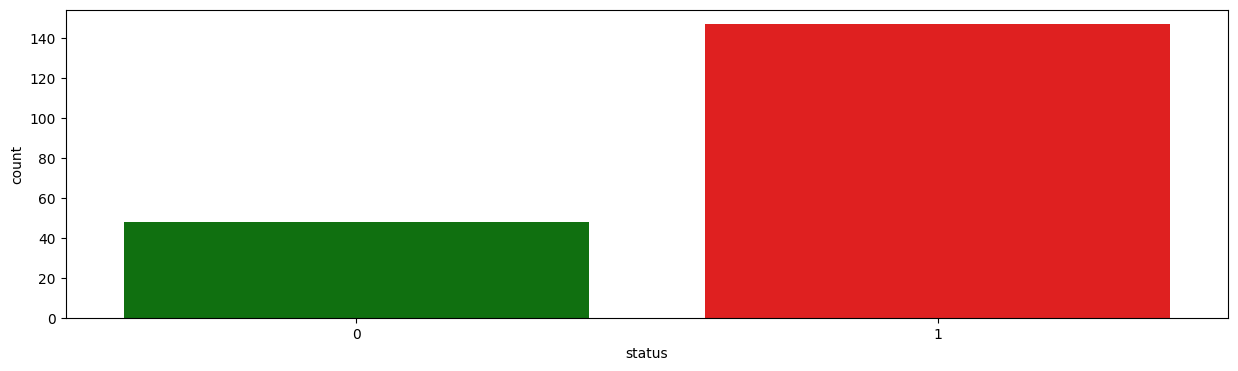

In [154]:
#Balance of Data
# Create a color palette with red for status=1 and default blue for status=0
colors = {0: 'green', 1: 'red'}
sns.countplot(x='status',data=df, palette=colors, hue='status', legend=False)

<Axes: >

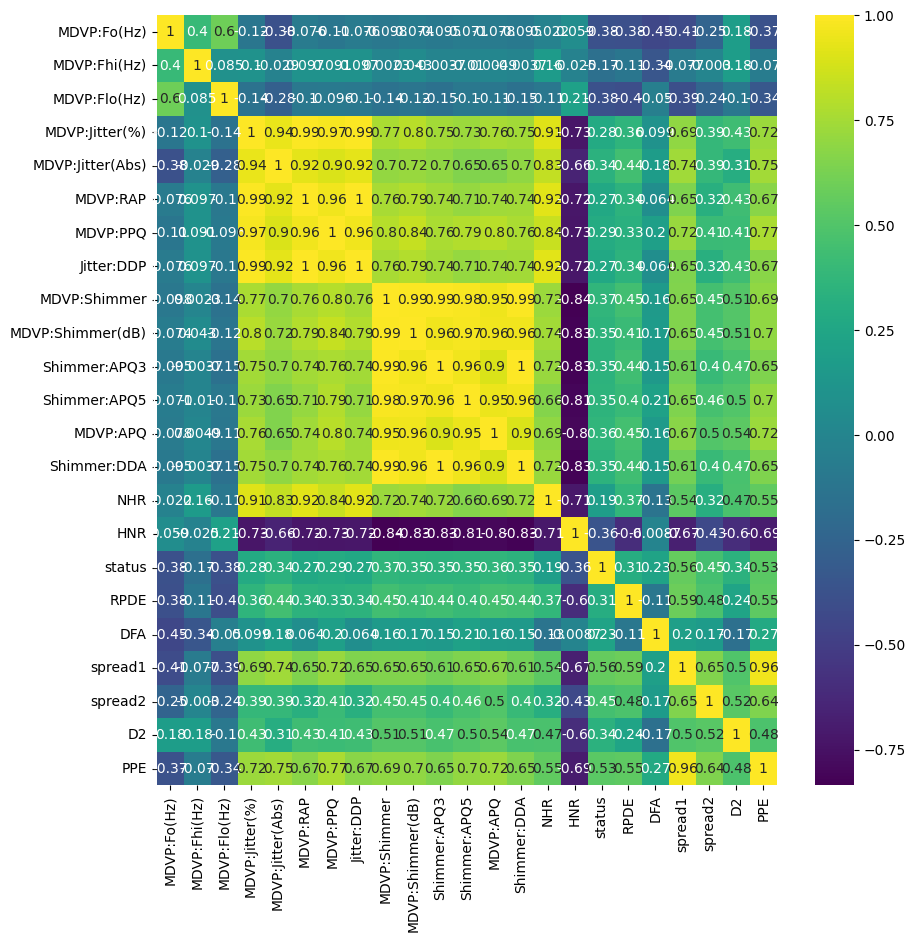

In [156]:
fig, ax = plt.subplots(figsize=(10,10))
# Drop the 'name' column specifically for the correlation calculation
df_numeric = df.drop(columns=['name'], errors='ignore')
sns.heatmap(df_numeric.corr(),annot=True,ax=ax, cmap='viridis') # Added cmap parameter

In this correlation heatmap, we can see that many features are closely related to each other.

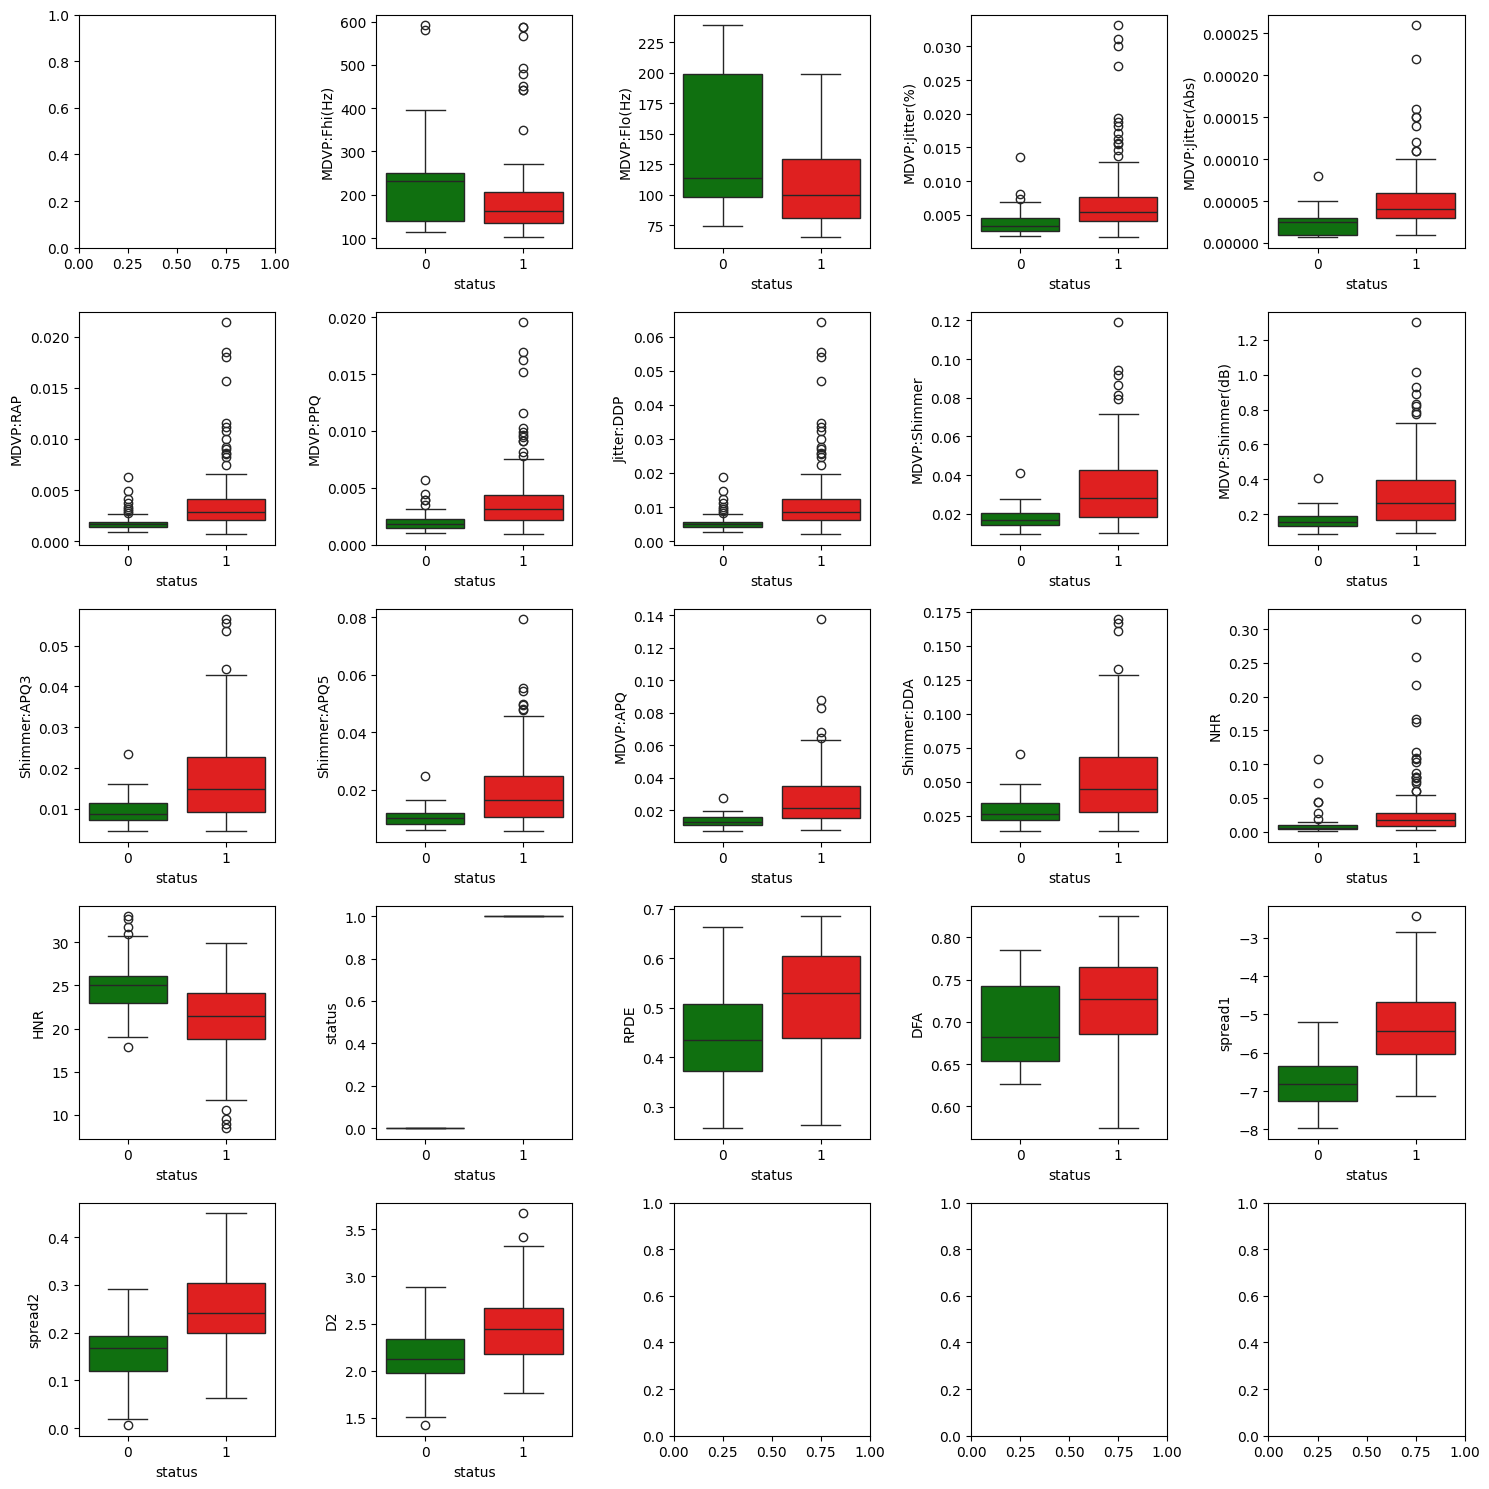

In [157]:
#Box Plot
fig,axes=plt.subplots(5,5,figsize=(15,15))
axes=axes.flatten()

# Define the color palette
colors = {0: 'green', 1: 'red'}

for i in range(1,len(df.columns)-1):
    sns.boxplot(x='status',y=df.iloc[:,i],data=df,orient='v',ax=axes[i], palette=colors, hue='status', legend=False) # Added palette, hue, and legend
plt.tight_layout()
plt.show()

From the boxplot shown above it is very evident that if a patient has a lower rate of 'HNR','MDVP:Flo(Hz)','MDVP:Fhi(Hz)','MDVP:Fo(Hz)' ,then he/she is affected by parkinsons disease.

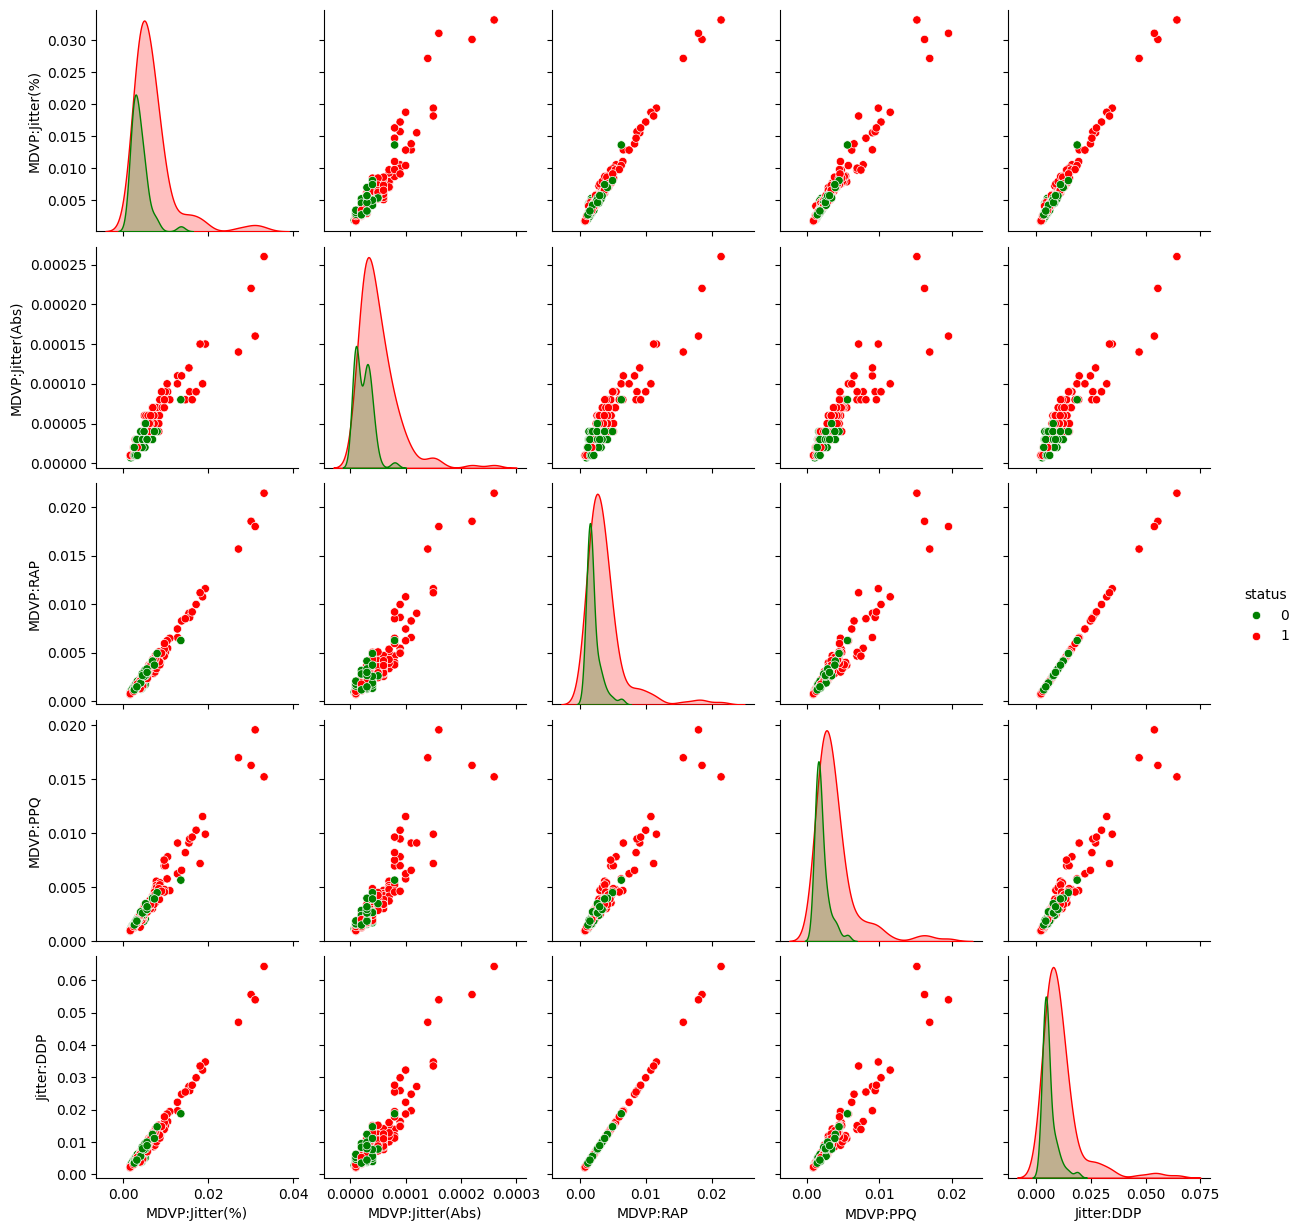

In [158]:
plt.rcParams['figure.figsize'] = (15, 4)
# Define the color palette
colors = {0: 'green', 1: 'red'}
sns.pairplot(df,hue = 'status', vars = ['MDVP:Jitter(%)','MDVP:Jitter(Abs)','MDVP:RAP','MDVP:PPQ', 'Jitter:DDP'], palette=colors ) # Added palette
plt.show()

From the above pair plot, we can see that all these fundamental frequencies are closely related to each other.

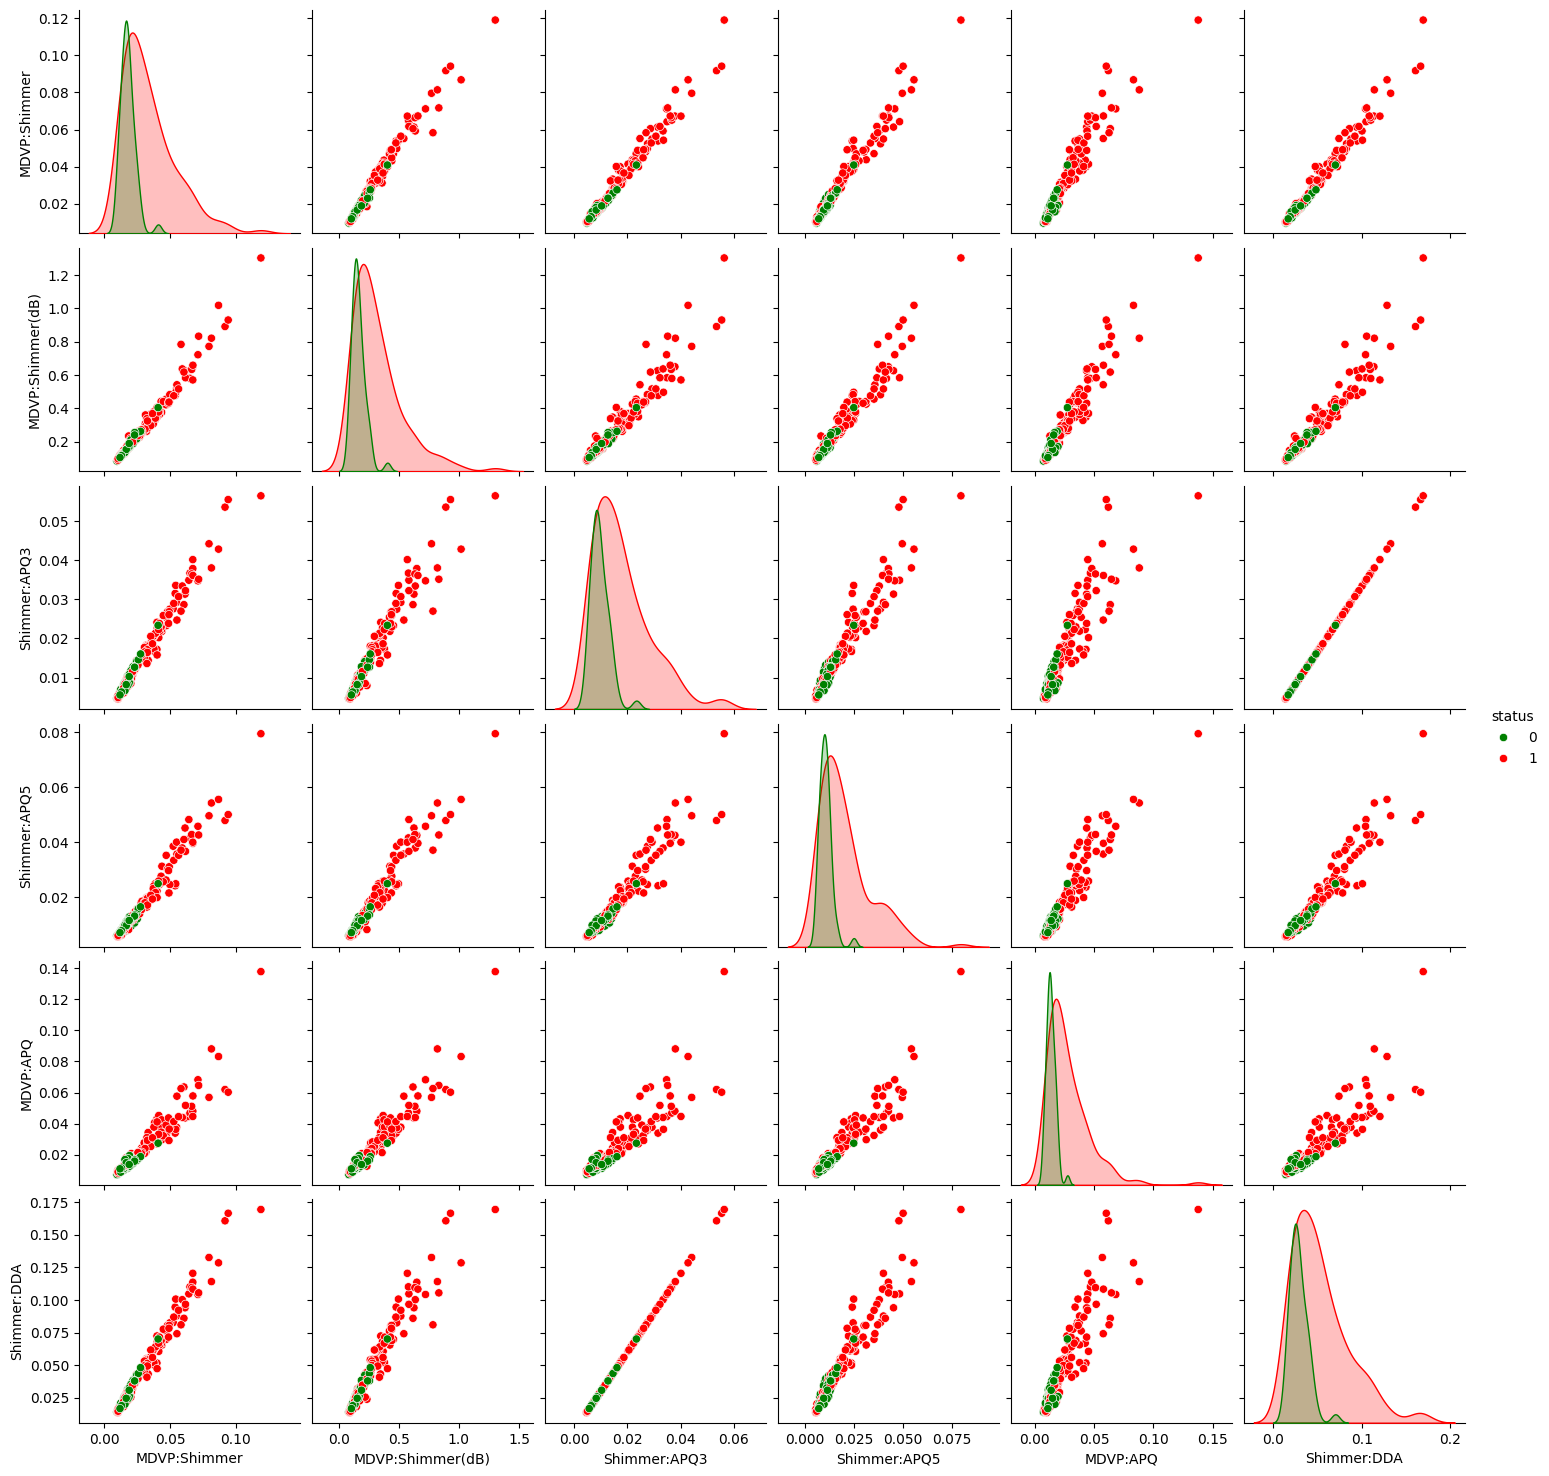

In [159]:
plt.rcParams['figure.figsize'] = (15, 4)
# Define the color palette
colors = {0: 'green', 1: 'red'}
sns.pairplot(df,hue = 'status', vars = ['MDVP:Shimmer','MDVP:Shimmer(dB)','Shimmer:APQ3','Shimmer:APQ5','MDVP:APQ','Shimmer:DDA'], palette=colors )
plt.show()

From the above pair plots, we can see that all these amplitude variation measures are highly correlated.

#Balancing the Data

In [160]:
# Exploring Imabalance In Dataset
df['status'].value_counts()

,count
status,
1,147
0,48


In [196]:
# Extracting Features Into Features & Target
X = df.drop(['status'], axis=1)
y = df['status']

print('Feature (X) Shape Before Balancing :', X.shape)
print('Target (y) Shape Before Balancing :', y.shape)

Feature (X) Shape Before Balancing : (195, 22)
Target (y) Shape Before Balancing : (195,)


Train-test-split

In [197]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)



The dataset is imbalanced, with more Parkinson's samples than non-Parkinson's. We will use SMOTE to balance it.

In [198]:
# Intialising SMOTE Object
from imblearn.over_sampling import SMOTE
sm = SMOTE(random_state=300)

In [199]:
# Resampling Data
X, y = sm.fit_resample(X, y)

In [200]:
# Balance training data using SMOTE
sm = SMOTE(random_state=300)
X_train_balanced, y_train_balanced = sm.fit_resample(X_train, y_train)

print('Feature (X_train_balanced) Shape After Balancing :', X_train_balanced.shape)
print('Target (y_train_balanced) Shape After Balancing :', y_train_balanced.shape)

Feature (X_train_balanced) Shape After Balancing : (236, 22)
Target (y_train_balanced) Shape After Balancing : (236,)


In [202]:
# Scale balanced training and test data
scaler_balanced = StandardScaler()
X_train_balanced_scaled = scaler_balanced.fit_transform(X_train_balanced)
X_test_scaled = scaler_balanced.transform(X_test)


# Machine Learning Model Training
 In this section, we have trained the following Machine Learning Models:
  + SVC
  + Decision Tree Classifier
  + Random Forest Classifier
  + Gradient boosting classifier

In [177]:
# Define models
from sklearn.ensemble import GradientBoostingClassifier

models = {
    'SVM': SVC(),
    'Decision Tree': DecisionTreeClassifier(random_state=42),
    'Random Forest': RandomForestClassifier(random_state=42),
    'Gradient Boosting': GradientBoostingClassifier(random_state=42)
}

Prepare results dictionary

In [178]:
results = {}


Model Training and Evaluation

In [179]:

#Train & Evaluate SVM
print("Training SVM...")
svm_model = SVC()
svm_model.fit(X_train_balanced_scaled, y_train_balanced)

svm_pred = svm_model.predict(X_test_scaled)

results['SVM'] = {
    'Accuracy': accuracy_score(y_test, svm_pred),
    'Precision': precision_score(y_test, svm_pred),
    'Recall': recall_score(y_test, svm_pred),
    'F1 Score': f1_score(y_test, svm_pred),
    'Model': svm_model
}


Training SVM...


In [180]:
#Train & Evaluate Decision Tree
print("Training Decision Tree...")
dt_model = DecisionTreeClassifier(random_state=42)
dt_model.fit(X_train_balanced_scaled, y_train_balanced)

dt_pred = dt_model.predict(X_test_scaled)

results['Decision Tree'] = {
    'Accuracy': accuracy_score(y_test, dt_pred),
    'Precision': precision_score(y_test, dt_pred),
    'Recall': recall_score(y_test, dt_pred),
    'F1 Score': f1_score(y_test, dt_pred),
    'Model': dt_model
}


Training Decision Tree...


In [181]:
#Tune & Evaluate Random Forest
print("Tuning Random Forest...")

rf_params = {
    'n_estimators': [50, 100],
    'max_depth': [None, 5, 10]
}

rf_grid = GridSearchCV(RandomForestClassifier(random_state=42),
                       rf_params, cv=3, scoring='f1')

rf_grid.fit(X_train_balanced_scaled, y_train_balanced)

best_rf = rf_grid.best_estimator_
rf_pred = best_rf.predict(X_test_scaled)

results['Random Forest'] = {
    'Accuracy': accuracy_score(y_test, rf_pred),
    'Precision': precision_score(y_test, rf_pred),
    'Recall': recall_score(y_test, rf_pred),
    'F1 Score': f1_score(y_test, rf_pred),
    'Model': best_rf
}


Tuning Random Forest...


In [182]:
#Tune & Evaluate Gradient Boosting
print("Tuning Gradient Boosting...")

gb_params = {
    'n_estimators': [50, 100],
    'learning_rate': [0.05, 0.1]
}

gb_grid = GridSearchCV(GradientBoostingClassifier(random_state=42),
                       gb_params, cv=3, scoring='f1')

gb_grid.fit(X_train_balanced_scaled, y_train_balanced)

best_gb = gb_grid.best_estimator_
gb_pred = best_gb.predict(X_test_scaled)

results['Gradient Boosting'] = {
    'Accuracy': accuracy_score(y_test, gb_pred),
    'Precision': precision_score(y_test, gb_pred),
    'Recall': recall_score(y_test, gb_pred),
    'F1 Score': f1_score(y_test, gb_pred),
    'Model': best_gb
}


Tuning Gradient Boosting...


#Displaying Model Performance

In [204]:
#Display all model results
print("\n=== Model Performance Summary ===")
for model_name, metrics in results.items():
    print(f"\n{model_name}:")
    print(f"Accuracy: {metrics['Accuracy']:.4f}")
    print(f"Precision: {metrics['Precision']:.4f}")
    print(f"Recall: {metrics['Recall']:.4f}")
    print(f"F1 Score: {metrics['F1 Score']:.4f}")



=== Model Performance Summary ===

SVM:
Accuracy: 0.8814
Precision: 0.9111
Recall: 0.9318
F1 Score: 0.9213

Decision Tree:
Accuracy: 0.8475
Precision: 0.8889
Recall: 0.9091
F1 Score: 0.8989

Random Forest:
Accuracy: 0.9492
Precision: 0.9362
Recall: 1.0000
F1 Score: 0.9670

Gradient Boosting:
Accuracy: 0.8983
Precision: 0.9318
Recall: 0.9318
F1 Score: 0.9318


In [209]:
from sklearn.model_selection import GridSearchCV
from sklearn.ensemble import RandomForestClassifier

# Define the parameter grid for tuning
param_grid = {
    'n_estimators': [100, 200, 300],
    'max_depth': [3, 5, 7, None],
    'min_samples_split': [2, 4, 6],
    'min_samples_leaf': [1, 2, 3]
}

# Initialize the model
rf = RandomForestClassifier(random_state=42)

# Apply GridSearchCV
grid = GridSearchCV(
    estimator=rf,
    param_grid=param_grid,
    cv=5,
    scoring='accuracy',
    n_jobs=-1,
    verbose=1
)

# Train using balanced + scaled dataset
grid.fit(X_train_balanced_scaled, y_train_balanced)

# Best Hyperparameters
print("Best Parameters Found:", grid.best_params_)

# Best Cross-Validation Accuracy
print("Best CV Accuracy:", grid.best_score_)

# Best Tuned Model
best_rf_model = grid.best_estimator_


Fitting 5 folds for each of 108 candidates, totalling 540 fits
Best Parameters Found: {'max_depth': 7, 'min_samples_leaf': 1, 'min_samples_split': 2, 'n_estimators': 300}
Best CV Accuracy: 0.936790780141844


#Training the Best Model on the Full Datase

In [210]:
# Select best model based on F1 Score
best_model_name = max(results, key=lambda x: results[x]['F1 Score'])
best_model = results[best_model_name]['Model']
print(f"\n Best model is: {best_model_name}")


 Best model is: Random Forest


In [211]:
# Train best model on full data
scaler_full = StandardScaler()
X_scaled_full = scaler_full.fit_transform(X)
best_model.fit(X_scaled_full, y)

print(f"Best model ({best_model_name}) trained on the full dataset.")


Best model (Random Forest) trained on the full dataset.


In [212]:
# Train best model on full data
scaler_full = StandardScaler()
X_scaled_full = scaler_full.fit_transform(X)
best_model.fit(X_scaled_full, y)

RandomForestClassifier(n_estimators=50, random_state=42)

In [218]:
# Accuracy on balanced + scaled training set
train_accuracy = accuracy_score(y_train_balanced, best_model.predict(X_train_balanced_scaled))
print(f"Training Accuracy: {train_accuracy:.4f}")

# Accuracy on test set
test_accuracy = accuracy_score(y_test, best_model.predict(X_test_scaled))
print(f"Testing Accuracy: {test_accuracy:.4f}")

Training Accuracy: 1.0000
Testing Accuracy: 0.9744


#Saving the Model and Scaler

In [213]:
#Save Best Model and Scaler
import pickle

# Save the best model
with open("best_model.pkl", "wb") as f:
    pickle.dump(best_model, f)

# Save the scaler
with open("scaler.pkl", "wb") as f:
    pickle.dump(scaler, f)

print("\n Model and scaler saved as 'best_model.pkl' and 'scaler.pkl'")


 Model and scaler saved as 'best_model.pkl' and 'scaler.pkl'


# Loading  the Model and Scaler

In [214]:
#Load Saved Model and Scaler
import pickle

# Load best model
best_model_loaded = pickle.load(open("best_model.pkl", "rb"))

# Load scaler
scaler_loaded = pickle.load(open("scaler.pkl", "rb"))

print("\n Model and scaler loaded as 'best_model.pkl' and 'scaler.pkl'")



 Model and scaler loaded as 'best_model.pkl' and 'scaler.pkl'


#Confusion Matrix & Classification Report

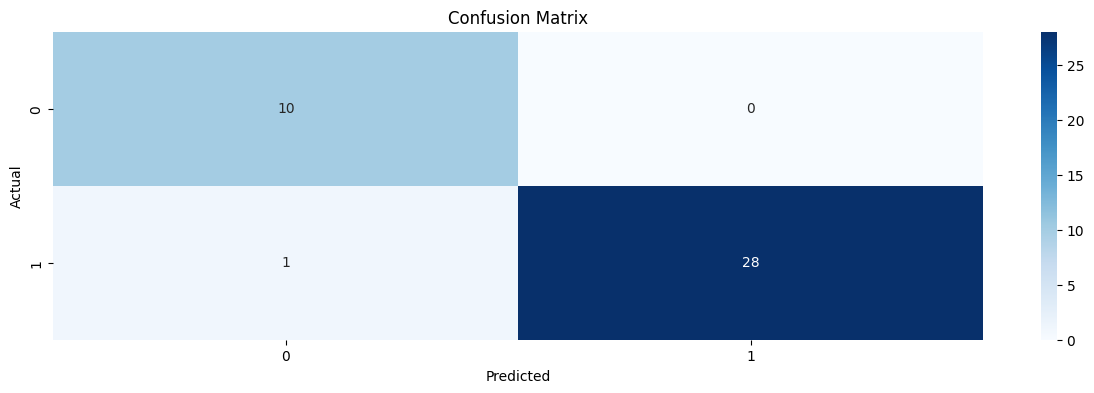


Classification Report:
              precision    recall  f1-score   support

           0       0.91      1.00      0.95        10
           1       1.00      0.97      0.98        29

    accuracy                           0.97        39
   macro avg       0.95      0.98      0.97        39
weighted avg       0.98      0.97      0.97        39



In [219]:
from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, best_model.predict(X_test_scaled))

sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")
plt.title("Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

print("\nClassification Report:")
print(classification_report(y_test, best_model.predict(X_test_scaled)))


Feature Importance (Random Forest only)

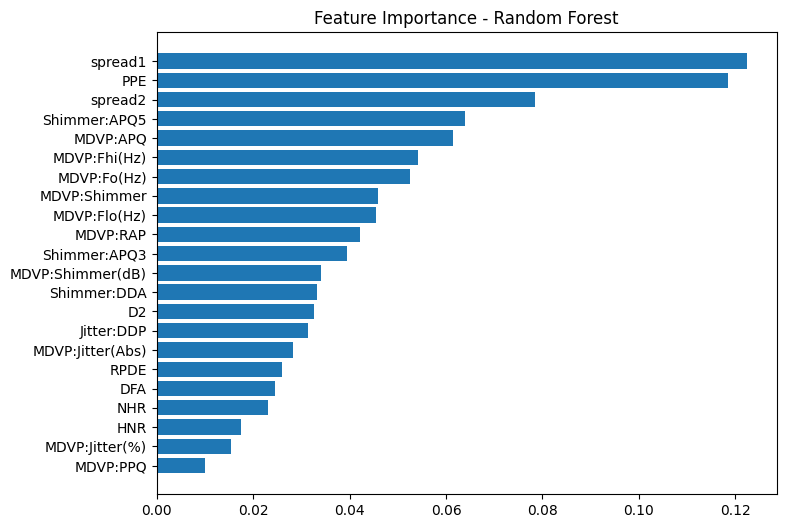

In [220]:
feature_importance = best_model.feature_importances_
features = X.columns
fi_df = pd.DataFrame({"Feature": features, "Importance": feature_importance})
fi_df = fi_df.sort_values(by="Importance", ascending=False)

plt.figure(figsize=(8,6))
plt.barh(fi_df["Feature"], fi_df["Importance"])
plt.title("Feature Importance - Random Forest")
plt.gca().invert_yaxis()
plt.show()


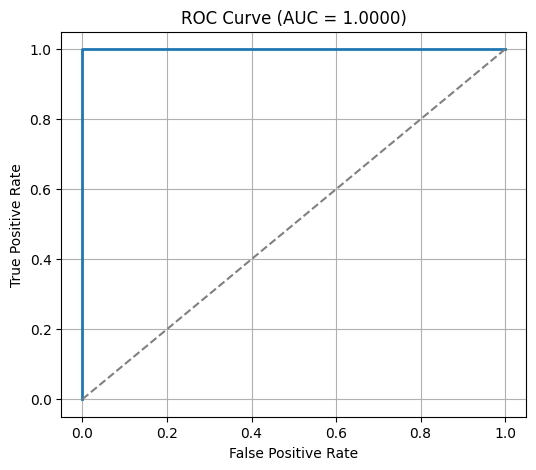

In [223]:
# ROC curve & AUC
from sklearn.metrics import roc_curve, roc_auc_score

# get probabilities for positive class
y_prob = best_model.predict_proba(X_test_scaled)[:, 1]

fpr, tpr, thresholds = roc_curve(y_test, y_prob)
auc = roc_auc_score(y_test, y_prob)

plt.figure(figsize=(6,5))
plt.plot(fpr, tpr, lw=2)
plt.plot([0,1], [0,1], linestyle='--', color='gray')
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title(f"ROC Curve (AUC = {auc:.4f})")
plt.grid(True)
plt.show()


#Building a Predictive System



In [217]:
import numpy as np
import pickle

#  Load the saved model and scaler
with open("best_model.pkl", "rb") as model_file:
    model = pickle.load(model_file)

with open("scaler.pkl", "rb") as scaler_file:
    scaler = pickle.load(scaler_file)

#  Example input data (Replace this with new input to test)
input_data = (197.07600,206.89600,192.05500,0.00289,0.00001,0.00166,0.00168,0.00498,
              0.01098,0.09700,0.00563,0.00680,0.00802,0.01689,0.00339,26.77500,0.422229,
              0.741367,-7.348300,0.177551,1.743867,0.085569)

#  Convert to numpy array
input_data_as_numpy_array = np.asarray(input_data)

#  Reshape for a single prediction
input_data_reshaped = input_data_as_numpy_array.reshape(1, -1)

#  Standardize input data
std_data = scaler.transform(input_data_reshaped)

#  Make prediction
prediction = model.predict(std_data)

#  Output result
if prediction[0] == 0:
    print(" The person does NOT have Parkinson's Disease")
else:
    print(" The person HAS Parkinson's Disease")


 The person HAS Parkinson's Disease


/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but MinMaxScaler was fitted with feature names
  warnings.warn(
